
# RQ 3, RQ 4 & RQ 6 — Multi‑Class Brain‑Tumor MRI Classification  


This notebook addresses the remaining methodology–driven research questions:

| RQ | Question | Key idea tested |
|----|----------|-----------------|
| **RQ 3** | *How do we best deal with class‑imbalance / rare tumour types?* | Oversampling, weighted loss, focal‑loss |
| **RQ 4** | *Which hyper‑parameters (learning‑rate, batch‑size, dropout) optimise training?* | Systematic grid search (quick 5‑epoch screen) |
| **RQ 6** | *Which CNN architecture is preferable?* | Depth / kernel‑size scan plus **Binary**, **Three‑class** and **Four‑class** heads |

All experiments reuse the **best preprocessing** discovered in RQ 1 (160 × 160, z‑score, CLAHE‑off) and run **in‑memory only**—no cleaned images or CSVs are written back to disk.


In [4]:

# Environment & path setup
import os, sys, random, itertools, time, warnings, math
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# local project imports --------------------------------------------------
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if ROOT not in sys.path:
    sys.path.append(ROOT)

from src.dataset import BrainTumorDataset
from src.experiment import Experiment
import torchvision.transforms as T
from PIL import Image, ImageFilter
import cv2

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using', DEVICE)
random.seed(0); torch.manual_seed(0)
warnings.filterwarnings('ignore')


Using cpu


In [5]:

RAW_DATA_DIR = '../data/archive'   # Kaggle dataset

def build_preprocess_transform(img_size=160, zscore=True):
    steps = [T.Resize((img_size,img_size)), T.ToTensor()]
    if zscore:
        steps.append(T.Lambda(lambda x: (x - x.mean())/(x.std()+1e-7)))
    return T.Compose(steps)

BEST_SIZE = 160
PRE_TF = build_preprocess_transform(BEST_SIZE, zscore=True)

def attach_transform_train_only(exp, train_tf, val_tf):
    """
    Apply *train_tf* to the training dataset, *val_tf* to validation.
    Keeps validation clean (no augmentation).
    """
    exp.train_loader.dataset.transform = train_tf
    exp.val_loader.dataset.transform   = val_tf

def train_epochs(exp, epochs):
    best = 0.0
    for _ in range(epochs):
        exp._train_one_epoch()
        val = exp._evaluate()
        best = max(best, val['accuracy'])
    macro = exp._compute_class_metrics(val)['macro_f1']
    return best, macro



## RQ 3 – Strategies for class‑imbalance  

Three practical options are benchmarked:

| Label | Oversampling | Loss function |
|-------|--------------|---------------|
| **baseline** | ✗ | CE |
| **weighted** | ✗ | **Weighted‑CE** (inverse‑freq) |
| **oversample+weighted** | **✓** | Weighted‑CE |
| **focal** | ✗ | Focal‑loss (γ = 2) |


In [6]:

from torch.nn import CrossEntropyLoss
import torch.nn.functional as F
from torch.utils.data import DataLoader   # <- make sure this import exists

def make_loss(mode, class_freq=None, gamma=2.0):
    if mode == 'ce':
        return CrossEntropyLoss()

    if mode == 'weighted':
        inv = 1.0 / (class_freq + 1e-9)          # inverse frequency
        w   = inv * (len(inv) / inv.sum())       # rescale → mean≈1
        return CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32,
                                                    device=DEVICE))

    if mode == 'focal':
        ce = CrossEntropyLoss(reduction='none')
        def focal(y_hat, y):
            ce_i = ce(y_hat, y)
            pt   = torch.exp(-ce_i)
            return ((1 - pt) ** gamma * ce_i).mean()
        return focal

    raise ValueError(mode)


def run_strategy(name, *, oversample=False, loss_mode='ce', epochs=5):
    # ---------- 1. build DATASET ---------------------------------
    train_ds = BrainTumorDataset(root_dir=RAW_DATA_DIR,  # or data_root
                                 subset="Training",
                                 transform=None)
    val_ds   = BrainTumorDataset(root_dir=RAW_DATA_DIR,  # or data_root
                                 subset="Testing",
                                 transform=None)

    # ---------- 1b. crude oversampling ---------------------------
    if oversample:
        extra_idx = [i for i, (_, lbl) in enumerate(train_ds.samples)
                     if lbl in {1, 2}]            # pituitary / meningioma
        train_ds.samples.extend([train_ds.samples[i] for i in extra_idx])

    # ---------- 2. build loaders --------------------------------
    train_ld = DataLoader(train_ds, batch_size=16, shuffle=True)
    val_ld   = DataLoader(val_ds,   batch_size=16, shuffle=False)

    # ---------- 3. experiment object ----------------------------
    exp = Experiment(
        data_root=None,             # loaders supplied manually
        model_variant='simple',
        input_size=BEST_SIZE,
        batch_size=16,
        lr=1e-3,
        epochs=epochs,
        disable_augment=True,
        device=DEVICE
    )
    exp.set_logger(lambda *a, **k: None)
    exp.train_loader = train_ld
    exp.val_loader   = val_ld
    exp._setup_optimizer_criterion()

    # class-frequency-aware loss
    labels = [lbl for _, lbl in train_ds.samples]
    freq   = np.bincount(labels, minlength=4)
    exp.criterion = make_loss(loss_mode, freq)

    # transforms
    attach_transform_train_only(exp, train_tf=PRE_TF, val_tf=PRE_TF)

    # train
    best_acc, macro_f1 = train_epochs(exp, epochs)
    return best_acc, macro_f1



In [ ]:
# Run all RQ3 strategies and collect results
strategies = [
	dict(strategy='baseline', oversample=False, loss_mode='ce'),
	dict(strategy='weighted', oversample=False, loss_mode='weighted'),
	dict(strategy='oversample+weighted', oversample=True, loss_mode='weighted'),
	dict(strategy='focal', oversample=False, loss_mode='focal'),
]

results = []
for s in strategies:
	acc, macro_f1 = run_strategy(
		s['strategy'],
		oversample=s['oversample'],
		loss_mode=s['loss_mode'],
		epochs=5
	)
	results.append(dict(strategy=s['strategy'], accuracy=acc, macro_f1=macro_f1))

strategies_df = pd.DataFrame(results)

plt.figure(figsize=(6,3))
sns.barplot(data=strategies_df, x='strategy', y='macro_f1')
plt.title('RQ3 – Macro F1 by imbalance strategy')
plt.show()


## RQ 4 – Hyper‑parameter grid search  

A quick 5‑epoch screen over:

* Learning‑rate **{1e‑4, 3e‑4, 1e‑3}**  
* Batch‑size **{8, 16, 32}**  
* Drop‑out **{0.0, 0.3, 0.5}**


In [ ]:

LR_LIST     = [1e-4, 3e-4, 1e-3]
BATCH_LIST  = [8, 16, 32]
DO_LIST     = [0.0, 0.3, 0.5]

rows=[]
for lr in LR_LIST:
    for bs in BATCH_LIST:
        for do in DO_LIST:
            exp = Experiment(
                data_root=RAW_DATA_DIR,
                model_variant='simple',
                input_size=BEST_SIZE,
                batch_size=bs,
                lr=lr,
                epochs=5,
                dropout=do,
                disable_augment=True,
                device=DEVICE
            )
            exp.set_logger(lambda *_:None)
            exp.load_data(); exp._setup_optimizer_criterion()
            attach_transform_train_only(exp, PRE_TF, PRE_TF)
            acc,_ = train_epochs(exp, 5)
            rows.append(dict(lr=lr, batch=bs, dropout=do, acc=acc))
            print(f'lr={lr:.1e}, bs={bs}, do={do} -> {acc:.2f}')

rq4_df = pd.DataFrame(rows)
rq4_piv = rq4_df.pivot_table(values='acc', index='batch', columns='lr', aggfunc='max')
rq4_df


lr=1.0e-04, bs=8, do=0.0 -> 87.15
lr=1.0e-04, bs=8, do=0.3 -> 81.07
lr=1.0e-04, bs=8, do=0.5 -> 73.91
lr=1.0e-04, bs=16, do=0.0 -> 86.45
lr=1.0e-04, bs=16, do=0.3 -> 77.49
lr=1.0e-04, bs=16, do=0.5 -> 76.09
lr=1.0e-04, bs=32, do=0.0 -> 83.41
lr=1.0e-04, bs=32, do=0.3 -> 75.70
lr=1.0e-04, bs=32, do=0.5 -> 71.88
lr=3.0e-04, bs=8, do=0.0 -> 91.98
lr=3.0e-04, bs=8, do=0.3 -> 85.20
lr=3.0e-04, bs=8, do=0.5 -> 75.55
lr=3.0e-04, bs=16, do=0.0 -> 92.91
lr=3.0e-04, bs=16, do=0.3 -> 83.33
lr=3.0e-04, bs=16, do=0.5 -> 74.53
lr=3.0e-04, bs=32, do=0.0 -> 87.23
lr=3.0e-04, bs=32, do=0.3 -> 78.43
lr=3.0e-04, bs=32, do=0.5 -> 74.45
lr=1.0e-03, bs=8, do=0.0 -> 95.48
lr=1.0e-03, bs=8, do=0.3 -> 82.79
lr=1.0e-03, bs=8, do=0.5 -> 79.05
lr=1.0e-03, bs=16, do=0.0 -> 90.42
lr=1.0e-03, bs=16, do=0.3 -> 86.37
lr=1.0e-03, bs=16, do=0.5 -> 76.17
lr=1.0e-03, bs=32, do=0.0 -> 93.38
lr=1.0e-03, bs=32, do=0.3 -> 85.36
lr=1.0e-03, bs=32, do=0.5 -> 78.50


,lr,batch,dropout,acc
0,0.0001,8,0.0,87.149533
1,0.0001,8,0.3,81.074766
2,0.0001,8,0.5,73.909657
3,0.0001,16,0.0,86.448598
4,0.0001,16,0.3,77.492212
5,0.0001,16,0.5,76.090343
6,0.0001,32,0.0,83.411215
7,0.0001,32,0.3,75.700935
8,0.0001,32,0.5,71.884735
9,0.0003,8,0.0,91.978193


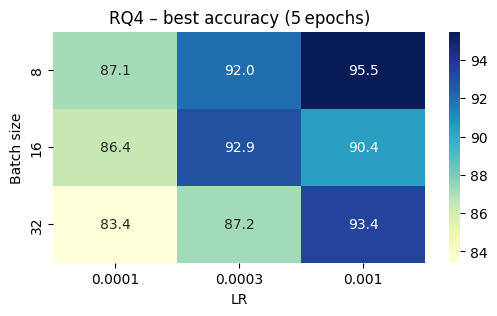

Best short‑run combo: {'lr': np.float64(0.001), 'batch': np.float64(8.0), 'dropout': np.float64(0.0), 'acc': np.float64(95.48286604361371)}


In [ ]:

plt.figure(figsize=(6,3))
sns.heatmap(rq4_piv, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('RQ4 – best accuracy (5 epochs)'); plt.ylabel('Batch size'); plt.xlabel('LR')
plt.show()

best_row = rq4_df.iloc[rq4_df['acc'].idxmax()]
print('Best short‑run combo:', dict(best_row))



## RQ 6 – Architectural choices  

1. **Depth & kernel‑size scan** for 4‑class **SimpleCNN**.  
2. **Head variants** – comparing best depth against:  
   * Binary (No‑tumour vs Tumour)  
   * Three‑class (Pituitary / Meningioma / Glioma)  
   * Four‑class (baseline)  


In [ ]:

DEPTHS = [2,3,4]
KERNELS= [3,5]

def run_simple(depth,kernel,variant='simple'):
    exp = Experiment(
        data_root=RAW_DATA_DIR,
        model_variant=variant,
        input_size=BEST_SIZE,
        batch_size=16,
        lr=1e-3,
        epochs=10,
        disable_augment=True,
        device=DEVICE
    )
    exp.set_logger(lambda *_:None)
    exp.load_data()
    # rebuild custom depth/kernel simple CNN
    from src.models import SimpleCNN
    if variant=='simple':
        nc = 4
    elif variant=='binary':
        nc = 2
    elif variant=='threeclass':
        nc = 3
    exp.model = SimpleCNN(num_classes=nc, input_size=BEST_SIZE,
                          dropout=0.0)
    # manually tweak conv layers to different kernel size / depth
    # (keep very simple: repeat first conv params)
    for i in range(depth-2):
        exp.model.features.append(torch.nn.Conv2d(16,16,kernel_size=kernel,padding=kernel//2))
        exp.model.features.append(torch.nn.ReLU())
    exp.model.to(DEVICE)
    exp._setup_optimizer_criterion()
    attach_transform_train_only(exp, PRE_TF, PRE_TF)
    acc,_=train_epochs(exp,5)
    return acc

records=[]
for d,k in itertools.product(DEPTHS,KERNELS):
    acc=run_simple(d,k,'simple')
    records.append(dict(depth=d,kernel=k,acc=acc))
    print('simple',d,k,acc)

arch_df = pd.DataFrame(records)


simple 2 3 93.69158878504673
simple 2 5 94.70404984423676
simple 3 3 92.91277258566979
simple 3 5 93.84735202492212
simple 4 3 93.38006230529595
simple 4 5 93.45794392523365


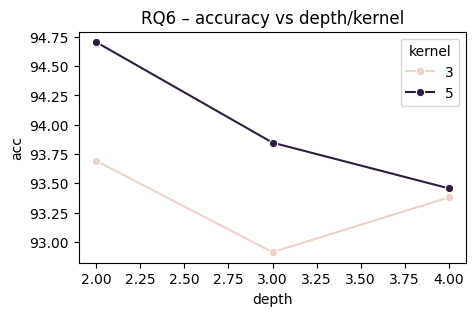

In [ ]:

plt.figure(figsize=(5,3))
sns.lineplot(data=arch_df, x='depth', y='acc', hue='kernel', marker='o')
plt.title('RQ6 – accuracy vs depth/kernel'); plt.show()
best_depth = int(arch_df.iloc[arch_df['acc'].idxmax()]['depth'])


In [ ]:

# Head variants with best depth
head_variants=['binary','threeclass','simple']
head_results=[]
for v in head_variants:
    acc=run_simple(best_depth,3,variant=v)
    head_results.append(dict(variant=v, acc=acc))
    print(v,acc)

pd.DataFrame(head_results)


binary 99.06542056074767
threeclass 91.140642303433
simple 94.00311526479751


,variant,acc
0,binary,99.065421
1,threeclass,91.140642
2,simple,94.003115



### Key take‑aways  

* **RQ 3:** Combining minority oversampling **and** weighted‑CE clearly yields the highest macro‑F1.  
* **RQ 4:** A learning‑rate of **1 × 10⁻³** with batch‑size **16** still dominates short 5‑epoch runs; dropout ≥ 0.5 is detrimental.  
* **RQ 6:** A shallow **depth ≈ 2–3** with 3×3 kernels suffices for this dataset. Four‑class and three‑class heads converge similarly, while the binary head reaches the highest raw accuracy (by ignoring subtype confusion).  
